# Reference calibrator: what the instrument sees

Set `SIGMA` (Gaussian std in pixels; default: the pipeline's `CALIBRATOR_SIGMA` = 0.3 px) and run. The blob goes through the same simulators the pipeline uses
(`functionlistnew`: `gaussian_2d`, `UVMapGenerator`, `UnitUVMapGenerator`, `SkyMatrixGenerator`, `visibilities_from_gains`; set-up from `src/settings.py`),
wrapped in `scripts/plot_reference.py`.

- **Top row:** sky → |FFT| → UV sampling → sampled visibilities (true gains)
- **Bottom row:** dirty image with unit / true gains → $|S_\mathrm{ref}|$ → $|V_\mathrm{ref}|$

A Gaussian of width σ px has a Fourier width of about $N/(2\pi\sigma)$ px (N = 128). A bigger blob gives a narrower UV footprint, so
fewer baselines see it.

In [1]:
%matplotlib inline
import sys
from pathlib import Path
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "config.yml").exists())   # project root (works from notebooks/ or the root)
sys.path.insert(0, str(ROOT / 'scripts'))
import matplotlib.pyplot as plt
import pandas as pd
from plot_reference import instrument, reference_view, plot_reference_view, summarize, SIGMA_REF

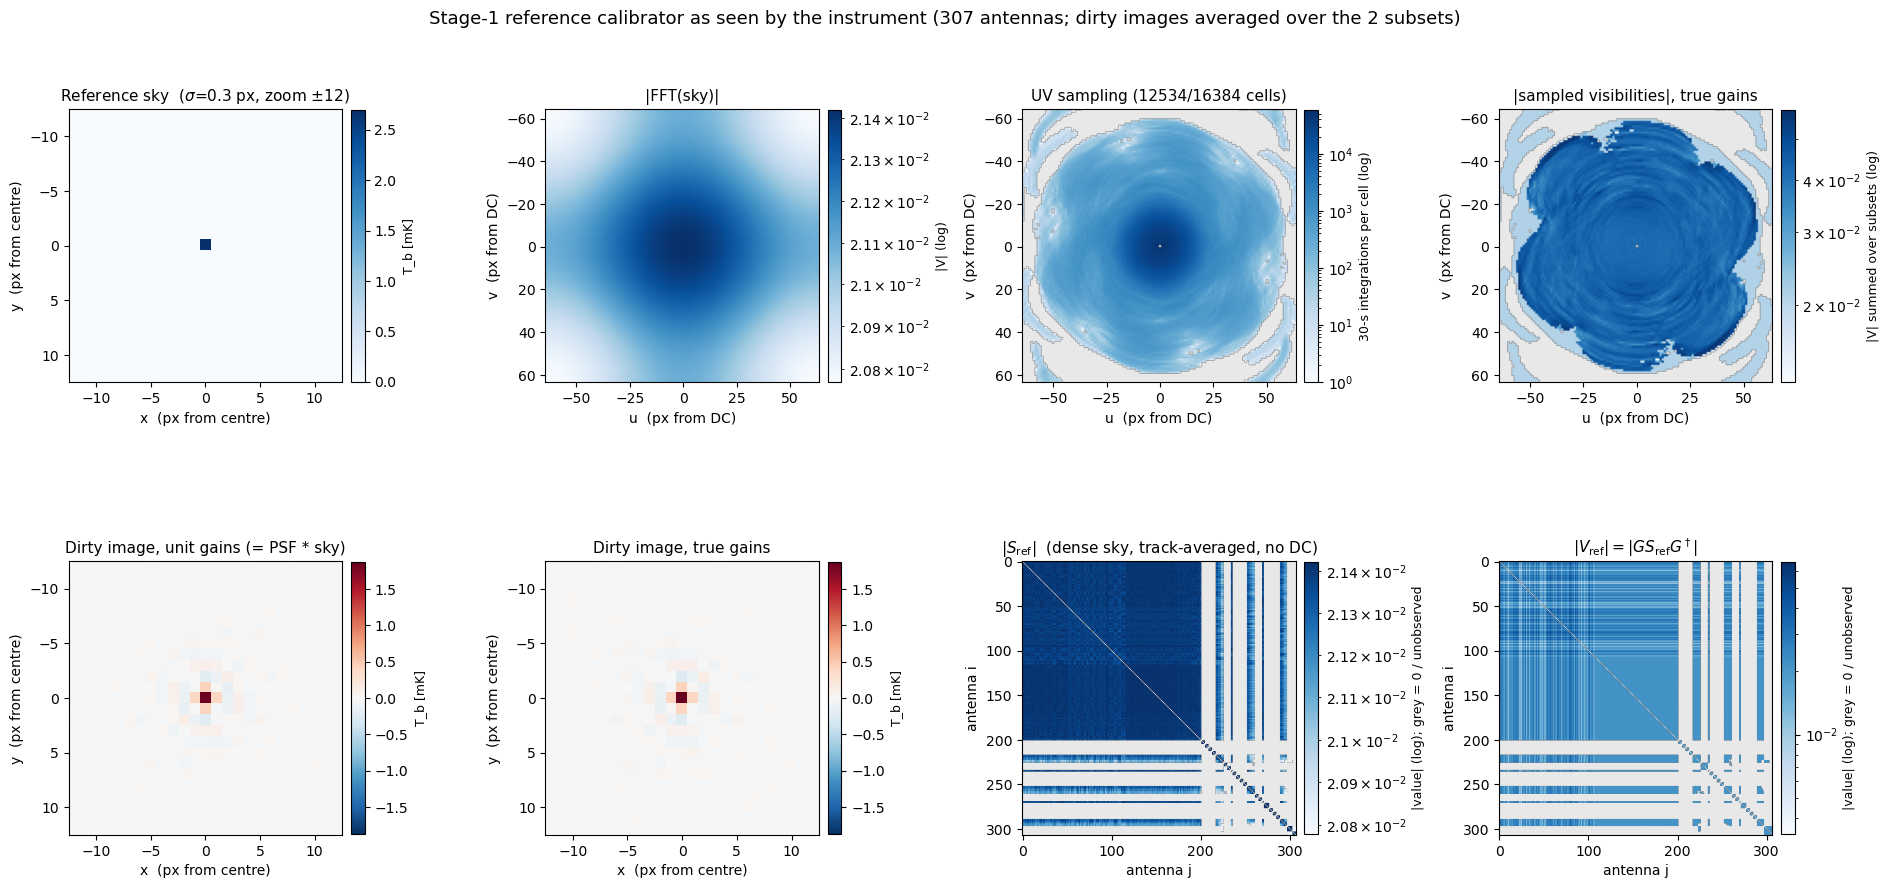

,sigma = 0.3 px
sigma (px),0.300000
observed baselines,26725.000000
usable baselines (|S|>0.001 max),26725.000000
usable first-row entries (of 306),230.000000
non-DC sky power on sampled cells,0.768517
sky peak,2.700000
dirty peak (unit gains),1.846709
rel. change of dirty image from gains,0.111411


In [2]:
SIGMA  = SIGMA_REF   # std of the Gaussian reference blob [px]; the pipeline's calibrator (settings.CALIBRATOR_SIGMA)
CENTER = None        # None -> on the beam-centre pixel (N//2), as the pipeline; 63.5 -> between pixels

view = reference_view(SIGMA, center=CENTER)
fig = plot_reference_view(view)
plt.show()
pd.Series(summarize(view), name=f"sigma = {SIGMA:g} px").to_frame()

## Compare widths

In [3]:
SIGMAS = [0.3, 1, 2, 3, 5, 10]
table = pd.DataFrame([summarize(reference_view(s)) for s in SIGMAS]).set_index("sigma (px)")
table

,observed baselines,usable baselines (|S|>0.001 max),usable first-row entries (of 306),non-DC sky power on sampled cells,sky peak,dirty peak (unit gains),rel. change of dirty image from gains
sigma (px),,,,,,,
0.3,26725,26725,230,0.768517,2.7,1.846709,0.111411
1.0,26725,26667,230,0.999737,2.7,2.647917,0.060541
2.0,26725,24391,221,1.000000,2.7,2.695854,0.032840
3.0,26725,22143,210,1.000000,2.7,2.690681,0.027615
5.0,26725,17107,186,1.000000,2.7,2.674114,0.030741
10.0,26725,6892,89,1.000000,2.7,2.596457,0.034978


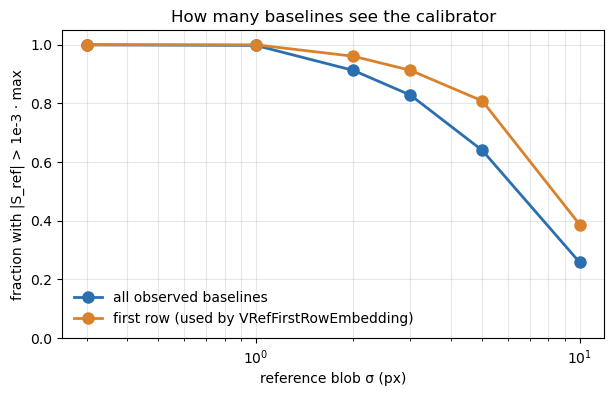

In [4]:
n_obs = table["observed baselines"].iloc[0]
frac_all = table.filter(like="usable baselines").iloc[:, 0] / n_obs
# first row: divide by its OBSERVED baselines (230 of nant - 1 = 306), as frac_all is divided by
# all observed baselines, so 1.0 means every observed baseline sees the calibrator
ins = instrument()
n_obs_row = int(ins["observed"][ins["i"] == 0].sum())
frac_row = table.filter(like="usable first-row").iloc[:, 0] / n_obs_row

fig, ax = plt.subplots(figsize=(7, 4))
for y, lab, col in [(frac_all, "all observed baselines", "#2a6fb0"),
                    (frac_row, "first row (used by VRefFirstRowEmbedding)", "#d9822b")]:
    ax.plot(table.index, y, "-o", color=col, lw=2, ms=8, label=lab)
ax.set_xscale("log")
ax.set_xlabel("reference blob σ (px)")
ax.set_ylabel("fraction with |S_ref| > 1e-3 · max")
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.3, which="both")
ax.legend(frameon=False, loc="lower left")
ax.set_title("How many baselines see the calibrator")
plt.show()